# Overfitting tests: how much of a Sharpe ratio survives the search?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon1706-lol/Aether-quant/blob/main/notebooks/03_overfitting_tests.ipynb)

Every backtest is the winner of some search. This notebook runs the project's checks on a 16-variant grid of the shipped trend rule:

1. **PBO by CSCV.** How often does the in-sample winner lose out of sample?
2. **Deflated Sharpe.** The best Sharpe is judged against the best expected from N trials. This shows how fast it falls as N grows.
3. **Minimum track record and the haircut Sharpe.** How long a record has to be, and what Sharpe is left after Bonferroni, Holm or BHY.
4. **A placebo test.**
5. **Holdout discipline.** A holdout read once, and a second read refused.
6. **Generations.** Capital moves from an old model to a new one by evidence, not all at once.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: install the library (numpy and pandas come with it)
    get_ipython().run_line_magic("pip", 'install -q "aether-quant[notebooks]>=6.6.5"')  # noqa: F821
else:  # a clone: run against the checkout's code
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "aether_quant" / "__init__.py").is_file():
            sys.path.insert(0, str(parent))
            break

In [2]:
from itertools import product

import numpy as np
import pandas as pd

from aether_quant import backtest, costs, hello, overfitting, samples

closes = samples.load_sample_prices()
start, end = "2022-01-01", "2026-10-31"
window = closes.loc[start:end]
grid = {}
for lookback_a, lookback_c in product((10, 20, 30, 40), (90, 120, 150, 180)):
    weights = hello.rule_weights(closes, start=start, end=end, params={"lookback_a": lookback_a, "lookback_b": 60, "lookback_c": lookback_c})
    run = backtest.backtest(weights.reindex(window.index), window, fill="close", cost_model=costs.coinbase_model(), periods_per_year=365, min_weight_change=0.002)
    grid[f"a{lookback_a}_c{lookback_c}"] = run.returns.iloc[1:]
returns = pd.DataFrame(grid)
sharpes = returns.apply(lambda column: backtest.summary_statistics(column, periods_per_year=365)["sharpe_ratio"])
print(f"{returns.shape[1]} variants, {len(returns)} days; best Sharpe {sharpes.max():.2f} ({sharpes.idxmax()}), median {sharpes.median():.2f}")

16 variants, 1764 days; best Sharpe 0.60 (a30_c180), median 0.47


## 1. PBO by combinatorially symmetric cross-validation

The history is cut into blocks. For every way of choosing half the blocks as in-sample, the best in-sample variant is ranked out of sample. PBO is the share of splits where it lands below the median.

In [3]:
usable = len(returns) - len(returns) % 8
result = overfitting.pbo(returns.to_numpy()[-usable:], blocks=8, periods_per_year=365)
print(f"PBO {result['pbo']:.2f}: the best-looking variant lands in the bottom half out of sample {result['pbo']:.0%} of the time")
pd.Series({key: value for key, value in result.items() if isinstance(value, (int, float))}).round(3)

PBO 0.66: the best-looking variant lands in the bottom half out of sample 66% of the time


pbo                         0.657
num_combinations           70.000
num_trials                 16.000
num_rows                 1760.000
blocks                      8.000
degradation_slope          -1.048
degradation_intercept       1.098
prob_oos_loss               0.200
dtype: float64

## 2. The deflated Sharpe falls as the number of trials grows

The same best variant, judged against the maximum Sharpe expected from N trials with this grid's spread of Sharpes. The project's own record stands at 217 trials.

PSR of the best variant against 0: 90.4%


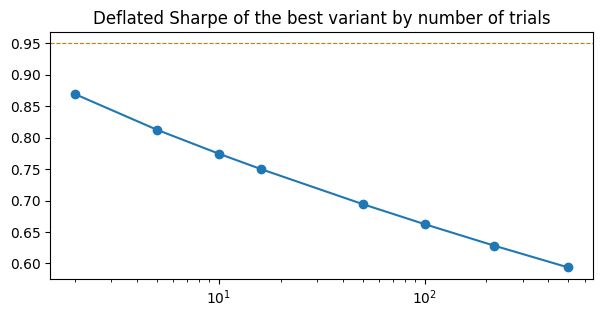

In [4]:
import matplotlib.pyplot as plt

best = returns[sharpes.idxmax()].to_numpy()
variance = float(np.var(sharpes, ddof=1))
curve = pd.Series({n: overfitting.deflated_sharpe_from_inputs(best, num_trials=n, trial_variance=variance, annualization=365)["value"] for n in (2, 5, 10, 16, 50, 100, 217, 500)})
print(f"PSR of the best variant against 0: {overfitting.probabilistic_sharpe_ratio(best, 0.0):.1%}")
axes = curve.plot(marker="o", logx=True, figsize=(7, 3.2), title="Deflated Sharpe of the best variant by number of trials")
axes.axhline(0.95, color="#d97706", linestyle="--", linewidth=0.8)
plt.show()

## 3. Minimum track record length and the haircut Sharpe

In [5]:
rows = {}
for method in ("bonferroni", "holm", "bhy"):
    cut = overfitting.haircut_sharpe(float(sharpes.max()), len(best), 217, method=method, periods_per_year=365)
    rows[method] = {"Sharpe": cut["sharpe"], "haircut Sharpe": cut["haircut_sharpe"], "haircut": cut["haircut"], "adjusted p": cut["adjusted_p_value"]}
print(f"Minimum track record for Sharpe > 0 at 95%: {overfitting.minimum_track_record_length(best, periods_per_year=365) / 365:.1f} years (the sample has {len(best) / 365:.1f})")
pd.DataFrame(rows).T.round(3)

Minimum track record for Sharpe > 0 at 95%: 7.7 years (the sample has 4.8)


,Sharpe,haircut Sharpe,haircut,adjusted p
bonferroni,0.602,0.0,1.0,1.0
holm,0.602,0.0,1.0,1.0
bhy,0.602,0.0,1.0,1.0


## 4. A placebo test

Shift the decisions by a random number of days, many times. A real timing signal should beat most of its own shifted copies. The p-value counts the observation itself, so it is never exactly zero.

In [6]:
rng = np.random.default_rng(7)
weights = hello.rule_weights(closes, start=start, end=end)
observed = backtest.backtest(weights.reindex(window.index), window, fill="close", cost_model=costs.coinbase_model(), periods_per_year=365).stats()["sharpe_ratio"]
placebos = []
for _ in range(30):
    shift = int(rng.integers(30, 300))
    shifted = weights.reindex(window.index).shift(shift)
    placebos.append(backtest.backtest(shifted, window, fill="close", cost_model=costs.coinbase_model(), periods_per_year=365).stats()["sharpe_ratio"])
print(f"observed Sharpe {observed:.2f}; placebo p-value {overfitting.placebo_p_value(observed, placebos):.2f} over {len(placebos)} time shifts")

observed Sharpe 0.43; placebo p-value 0.29 over 30 time shifts


## 5. A holdout is read once

The project's research rounds write every holdout read to a ledger before the read. A second read of the same cell is refused, so nobody can peek at the holdout and then try again.

In [7]:
import tempfile

from aether_quant import cycle

ledger = Path(tempfile.mkdtemp()) / "holdout_ledger.jsonl"
cycle.record_holdout_read(ledger, candidate="my_signal", cells=("V1",), digest="abc", created_at="2026-11-08T12:00:00Z")
try:
    cycle.record_holdout_read(ledger, candidate="my_signal_v2", cells=("V1",), digest="def", created_at="2026-11-09T12:00:00Z")
except PermissionError as refused:
    print("refused:", refused)

refused: cells ['V1'] have already been read: a holdout is read once


## 6. Generations hand over by evidence

A new model starts at a small share and gains capital on a fixed glide. A tripped guard takes its risk off at once.

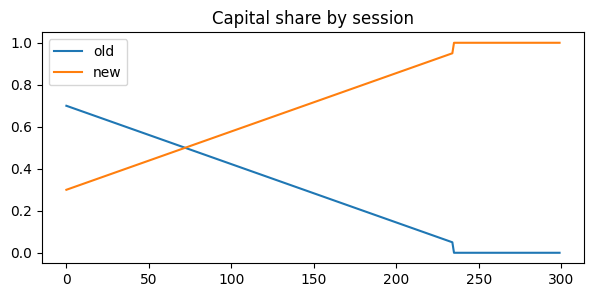

In [8]:
policy = cycle.GlidePolicy(glide_sessions=252, entry_share=0.30, retire_share=0.05)
shares, path = {"old": 1.0, "new": 0.0}, []
for session in range(300):
    shares = cycle.update_generation_shares(shares, {"old": "active", "new": "ramping"}, {}, {}, policy)
    path.append(dict(shares))
axes = pd.DataFrame(path).plot(figsize=(7, 3), title="Capital share by session")
plt.show()

*Nothing in this project has passed these tests yet: 217 pre-registered trials, no survivor, and the holdouts still unread. That is the point of running them.*